In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

In [51]:
df = pd.read_csv("car data.csv")

print("Shape:", df.shape)
display(df.head())

Shape: (301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [52]:
print("Columns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
display(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe(include="all").T)

Columns:
['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner']

Data Types:
Car_Name             str
Year               int64
Selling_Price    float64
Present_Price    float64
Kms_Driven         int64
Fuel_Type            str
Seller_Type          str
Transmission         str
Owner              int64
dtype: object

Missing Values:


Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64


Duplicate Rows:
2

Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Car_Name,301,98,city,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,301.0,NaN,NaN,NaN,2013.627907,2.891554,2003.0,2012.0,2014.0,2016.0,2018.0
Selling_Price,301.0,NaN,NaN,NaN,4.661296,5.082812,0.1,0.9,3.6,6.0,35.0
Present_Price,301.0,NaN,NaN,NaN,7.628472,8.644115,0.32,1.2,6.4,9.9,92.6
Kms_Driven,301.0,NaN,NaN,NaN,36947.20598,38886.883882,500.0,15000.0,32000.0,48767.0,500000.0
Fuel_Type,301,3,Petrol,239,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Seller_Type,301,2,Dealer,195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transmission,301,2,Manual,261,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Owner,301.0,NaN,NaN,NaN,0.043189,0.247915,0.0,0.0,0.0,0.0,3.0


In [53]:
missing = df.isnull().sum()

if missing.sum() == 0:
    print("No missing values found.")
else:
    print("Missing values found:")
    display(missing[missing > 0])

No missing values found.


In [54]:
duplicate_count = df.duplicated().sum()

print("Duplicates before treatment:", duplicate_count)

if duplicate_count > 0:
    df = df.drop_duplicates().reset_index(drop=True)

print("Duplicates after treatment:", df.duplicated().sum())
print("Updated shape:", df.shape)

Duplicates before treatment: 2
Duplicates after treatment: 0
Updated shape: (299, 9)


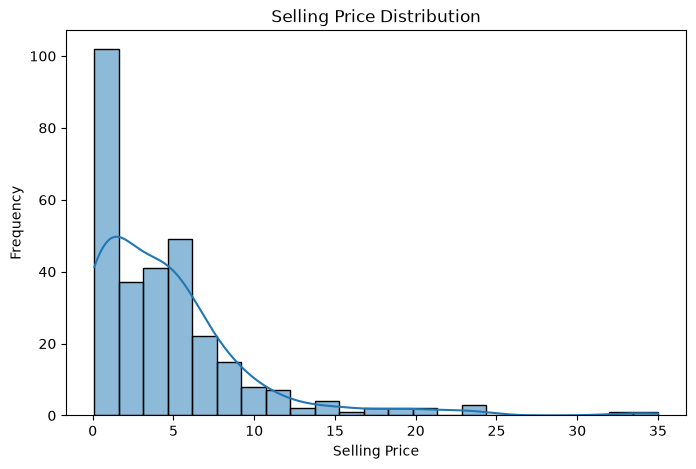

In [55]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["Selling_Price"],
    kde=True
)

plt.title("Selling Price Distribution")
plt.xlabel("Selling Price")
plt.ylabel("Frequency")
plt.show()

In [56]:
### Target Distribution Observation

###The Selling_Price distribution shows the range and concentration of vehicle selling prices. The distribution helps identify whether the target is symmetric or skewed and provides an initial understanding of the prediction problem.

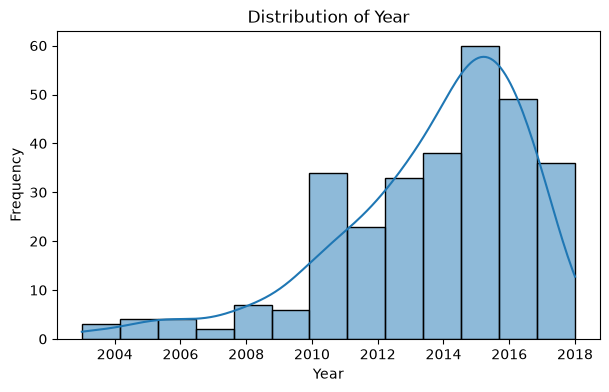

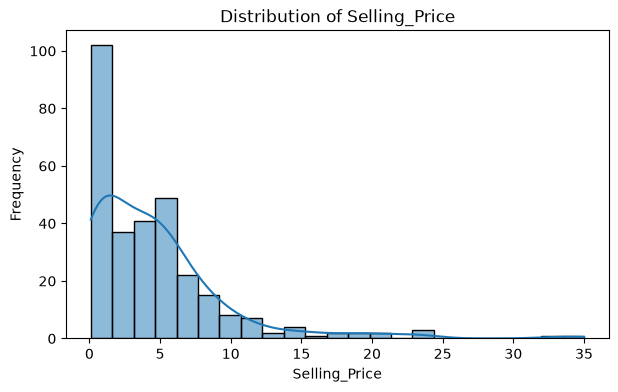

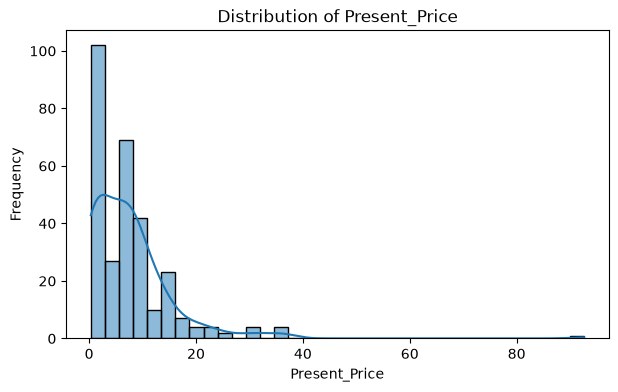

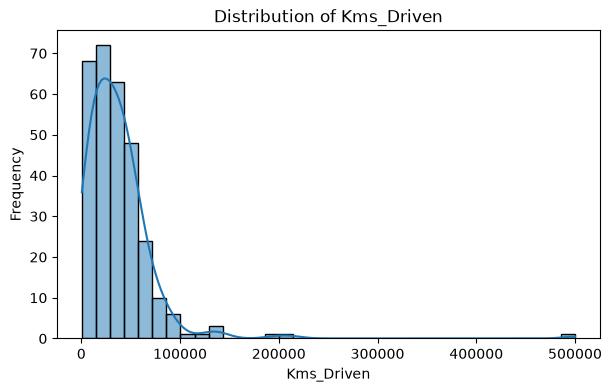

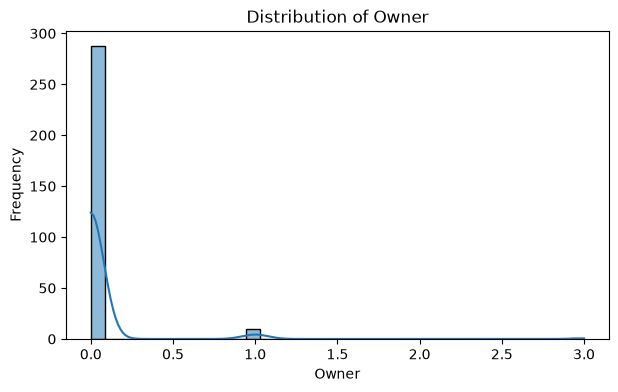

In [57]:
numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    plt.figure(figsize=(7, 4))
    sns.histplot(df[col], kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

In [58]:
### Numerical Feature Observation

###The numerical features have different ranges and distributions. Some variables may be skewed or concentrated within particular ranges. Scaling is therefore applied later inside the preprocessing pipeline.

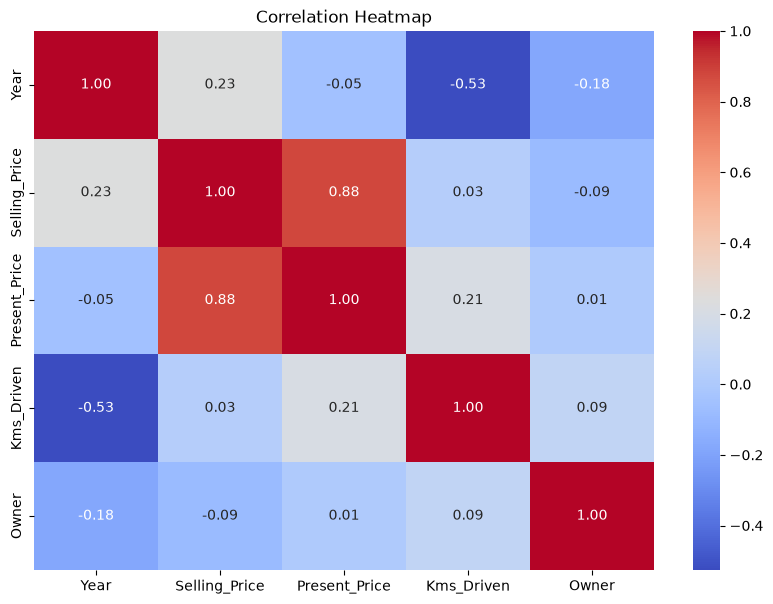

In [59]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [60]:
### Correlation Observation

###The correlation matrix shows the strength and direction of relationships between numerical variables. In particular, the relationship between Present_Price and Selling_Price is useful for understanding vehicle price prediction. Correlation does not by itself establish causation.

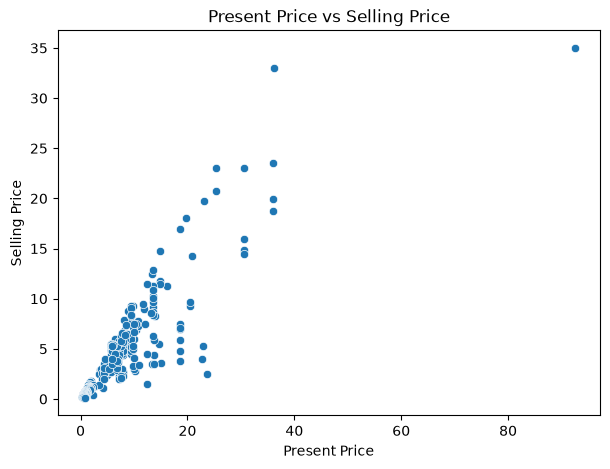

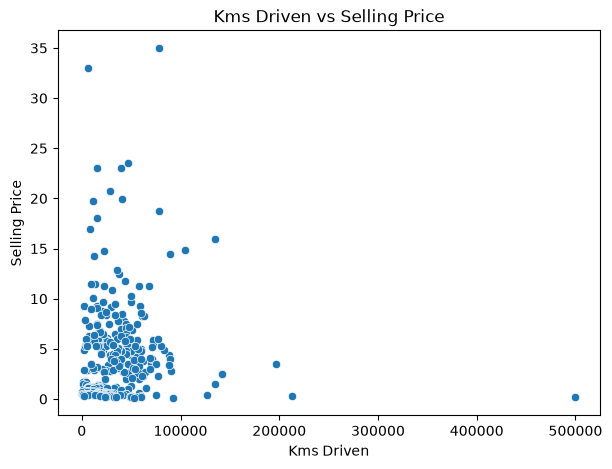

In [61]:
plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=df,
    x="Present_Price",
    y="Selling_Price"
)

plt.title("Present Price vs Selling Price")
plt.xlabel("Present Price")
plt.ylabel("Selling Price")
plt.show()


plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=df,
    x="Kms_Driven",
    y="Selling_Price"
)

plt.title("Kms Driven vs Selling Price")
plt.xlabel("Kms Driven")
plt.ylabel("Selling Price")
plt.show()

In [62]:
### Feature-Target Observations

###**Present_Price vs Selling_Price:**  
###The scatter plot shows the relationship between the current vehicle price and its selling price. A positive relationship would indicate that vehicles with higher present prices tend to have higher selling prices.

###**Kms_Driven vs Selling_Price:**  
###The scatter plot shows how vehicle usage relates to selling price. Higher usage may be associated with changes in resale value, although the relationship should be interpreted together with other features.

In [63]:
numeric_cols = df.select_dtypes(include=np.number).columns

outlier_summary = []

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    count = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ).sum()

    outlier_summary.append([
        col,
        count,
        lower_bound,
        upper_bound
    ])

outlier_df = pd.DataFrame(
    outlier_summary,
    columns=[
        "Feature",
        "Outlier Count",
        "Lower Bound",
        "Upper Bound"
    ]
)

display(outlier_df)

,Feature,Outlier Count,Lower Bound,Upper Bound
0,Year,7,2006.000,2022.000
1,Selling_Price,16,-6.875,13.725
2,Present_Price,14,-11.760,22.800
3,Kms_Driven,8,-35825.250,99708.750
4,Owner,11,0.000,0.000


In [64]:
### Outlier Treatment

###Potential outliers were identified using the IQR method. The detected extreme observations are not automatically removed because they may represent legitimate vehicles with relatively high prices, mileage, or other characteristics.

###Therefore, the observations are retained unless they are identified as erroneous records. The models are evaluated using the original valid observations.

In [65]:
REFERENCE_YEAR = 2026

df["Car_Age"] = REFERENCE_YEAR - df["Year"]

df["Brand"] = (
    df["Car_Name"]
    .astype(str)
    .str.split()
    .str[0]
)

df = df.drop(
    columns=["Car_Name", "Year"]
)

display(df.head())

,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Car_Age,Brand
0,3.35,5.59,27000,Petrol,Dealer,Manual,0,12,ritz
1,4.75,9.54,43000,Diesel,Dealer,Manual,0,13,sx4
2,7.25,9.85,6900,Petrol,Dealer,Manual,0,9,ciaz
3,2.85,4.15,5200,Petrol,Dealer,Manual,0,15,wagon
4,4.60,6.87,42450,Diesel,Dealer,Manual,0,12,swift


In [66]:
### Feature Engineering

###**Car_Age** is created from the vehicle's manufacturing year because vehicle age is directly relevant to resale value.

###**Brand** is extracted from Car_Name because different vehicle brands may have different resale values and market demand.

###Car_Name and Year are removed after creating these more useful features.

In [67]:
X = df.drop(columns=["Selling_Price"])
y = df["Selling_Price"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (299, 8)
Target shape: (299,)


In [68]:
# Create target bins only for stratification
y_bins = pd.qcut(
    y,
    q=5,
    labels=False,
    duplicates="drop"
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_bins
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (239, 8)
Testing data: (60, 8)


In [69]:
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])

preprocessor = ColumnTransformer([
    (
        "num",
        numeric_transformer,
        numerical_features
    ),
    (
        "cat",
        categorical_transformer,
        categorical_features
    )
])

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['Present_Price', 'Kms_Driven', 'Owner', 'Car_Age']
Categorical features: ['Fuel_Type', 'Seller_Type', 'Transmission', 'Brand']


In [70]:
models = {
    "Linear Regression": LinearRegression(),

    "Ridge": Ridge(alpha=1.0),

    "Lasso": Lasso(
        alpha=0.01,
        max_iter=10000
    ),

    "ElasticNet": ElasticNet(
        alpha=0.01,
        l1_ratio=0.5,
        max_iter=10000
    ),

    "Polynomial Regression": Pipeline([
        (
            "poly",
            PolynomialFeatures(
                degree=2,
                include_bias=False
            )
        ),
        ("reg", LinearRegression())
    ]),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=10,
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=RANDOM_STATE
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=RANDOM_STATE
    ),

    "SVR": SVR(
        C=10,
        kernel="rbf"
    ),

    "KNN": KNeighborsRegressor(
        n_neighbors=5
    )
}

In [71]:
results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)

    results.append([
        name,
        r2,
        rmse,
        mae
    ])

    trained_models[name] = pipeline

results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "R2",
        "RMSE",
        "MAE"
    ]
).sort_values(
    "R2",
    ascending=False
).reset_index(drop=True)

display(results_df)

,Model,R2,RMSE,MAE
0,SVR,0.939698,0.951430,0.521707
1,KNN,0.905382,1.191783,0.739433
2,Gradient Boosting,0.896800,1.244661,0.597612
3,ElasticNet,0.811049,1.684169,1.144449
4,Ridge,0.797919,1.741704,1.160729
5,Lasso,0.793296,1.761511,1.148734
6,Random Forest,0.766983,1.870274,0.790014
7,Linear Regression,0.722704,2.040251,1.263986
8,Decision Tree,0.631308,2.352573,1.004599
9,Polynomial Regression,0.555497,2.583147,1.414191


In [73]:
poly_results = []

for degree in [2, 3]:

    poly_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        (
            "poly",
            PolynomialFeatures(
                degree=degree,
                include_bias=False
            )
        ),
        ("model", LinearRegression())
    ])

    poly_pipeline.fit(X_train, y_train)

    pred = poly_pipeline.predict(X_test)

    poly_results.append([
        degree,
        r2_score(y_test, pred),
        np.sqrt(mean_squared_error(y_test, pred)),
        mean_absolute_error(y_test, pred)
    ])

poly_results_df = pd.DataFrame(
    poly_results,
    columns=[
        "Degree",
        "R2",
        "RMSE",
        "MAE"
    ]
)

display(poly_results_df)

,Degree,R2,RMSE,MAE
0,2,0.555497,2.583147,1.414191
1,3,-1382.267194,144.100187,32.343390


In [74]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    (
        "model",
        RandomForestRegressor(
            random_state=RANDOM_STATE
        )
    )
])

rf_params = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5]
}

rf_grid = GridSearchCV(
    rf_pipeline,
    rf_params,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

rf_pred = rf_grid.predict(X_test)

rf_r2 = r2_score(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_mae = mean_absolute_error(y_test, rf_pred)

print("Best RF Parameters:")
print(rf_grid.best_params_)

print("\nTuned Random Forest")
print("R2:", rf_r2)
print("RMSE:", rf_rmse)
print("MAE:", rf_mae)

Best RF Parameters:
{'model__max_depth': 10, 'model__min_samples_split': 2, 'model__n_estimators': 300}

Tuned Random Forest
R2: 0.7916522165873284
RMSE: 1.7685036018465972
MAE: 0.7680310820731291


In [76]:
gb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    (
        "model",
        GradientBoostingRegressor(
            random_state=RANDOM_STATE
        )
    )
])

gb_params = {
    "model__n_estimators": [100, 200],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_depth": [2, 3, 4]
}

gb_grid = GridSearchCV(
    gb_pipeline,
    gb_params,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

gb_grid.fit(X_train, y_train)

gb_pred = gb_grid.predict(X_test)

gb_r2 = r2_score(y_test, gb_pred)
gb_rmse = np.sqrt(mean_squared_error(y_test, gb_pred))
gb_mae = mean_absolute_error(y_test, gb_pred)

print("Best GB Parameters:")
print(gb_grid.best_params_)

print("\nTuned Gradient Boosting")
print("R2:", gb_r2)
print("RMSE:", gb_rmse)
print("MAE:", gb_mae)

Best GB Parameters:
{'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 200}

Tuned Gradient Boosting
R2: 0.8722648745602811
RMSE: 1.3847350206465197
MAE: 0.7743356125811207


In [77]:
baseline_rf_r2 = results_df.loc[
    results_df["Model"] == "Random Forest",
    "R2"
].iloc[0]

baseline_gb_r2 = results_df.loc[
    results_df["Model"] == "Gradient Boosting",
    "R2"
].iloc[0]

improvement_df = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Gradient Boosting"
    ],

    "Baseline R2": [
        baseline_rf_r2,
        baseline_gb_r2
    ],

    "Tuned R2": [
        rf_r2,
        gb_r2
    ]
})

improvement_df["R2 Improvement"] = (
    improvement_df["Tuned R2"] -
    improvement_df["Baseline R2"]
)

display(improvement_df)

,Model,Baseline R2,Tuned R2,R2 Improvement
0,Random Forest,0.766983,0.791652,0.024669
1,Gradient Boosting,0.896800,0.872265,-0.024535


In [78]:
# 5-fold cross-validation for the two best-performing models

svr_cv = cross_val_score(
    trained_models["SVR"],
    X_train,
    y_train,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

knn_cv = cross_val_score(
    trained_models["KNN"],
    X_train,
    y_train,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

cv_results = pd.DataFrame({
    "Model": [
        "SVR",
        "KNN"
    ],

    "Mean CV R2": [
        svr_cv.mean(),
        knn_cv.mean()
    ],

    "Std CV R2": [
        svr_cv.std(),
        knn_cv.std()
    ]
})

display(cv_results)

,Model,Mean CV R2,Std CV R2
0,SVR,0.840232,0.183424
1,KNN,0.906593,0.048099


In [79]:
# Select the best-performing model based on test-set R2

best_model_name = results_df.loc[
    results_df["R2"].idxmax(),
    "Model"
]

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)
print("Test R2:", results_df["R2"].max())

Best Model: SVR
Test R2: 0.9396981989651713


In [80]:
# Predictions using the best-performing model

best_predictions = best_model.predict(X_test)

print("Best Model Predictions Generated Successfully")

Best Model Predictions Generated Successfully


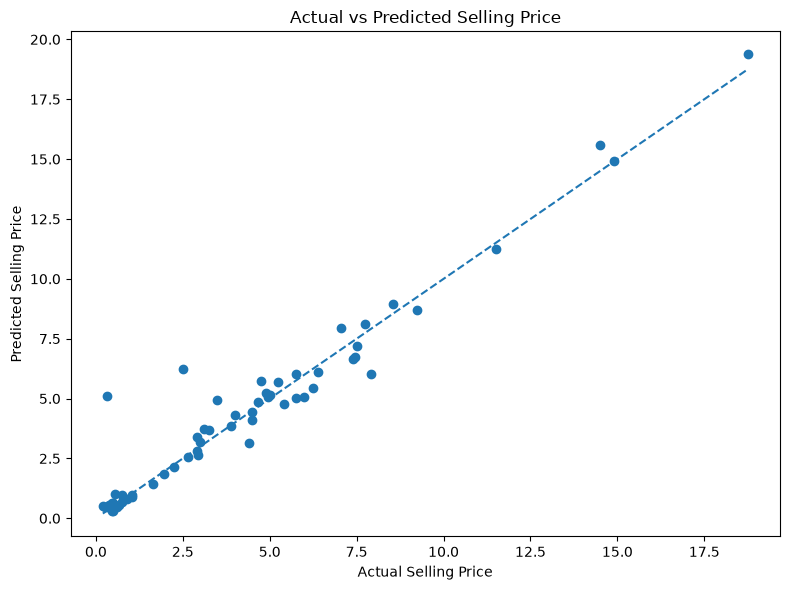

In [81]:
# Actual vs Predicted

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    best_predictions
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.title("Actual vs Predicted Selling Price")
plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")

plt.tight_layout()
plt.show()

In [82]:
### Observation

###The actual versus predicted plot compares the predicted selling prices with the actual selling prices. Points closer to the diagonal reference line indicate more accurate predictions. The plot helps visually assess how well the selected regression model predicts vehicle selling prices.

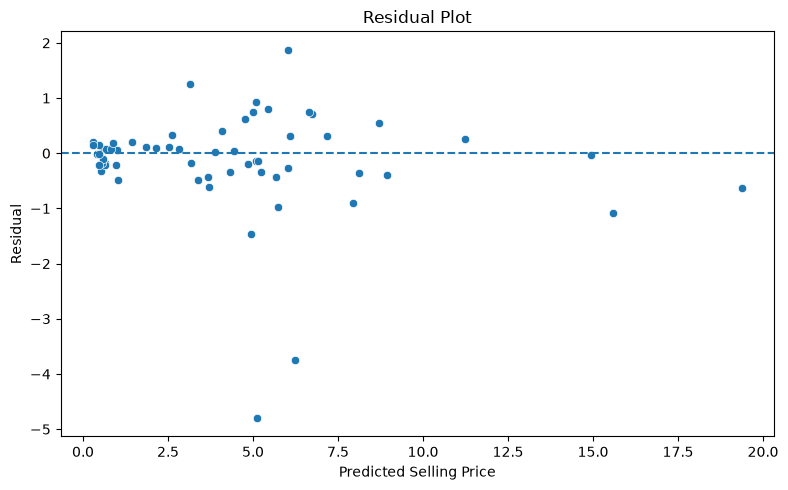

In [83]:
# Residual Plot

residuals = y_test - best_predictions

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=best_predictions,
    y=residuals
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title("Residual Plot")
plt.xlabel("Predicted Selling Price")
plt.ylabel("Residual")

plt.tight_layout()
plt.show()

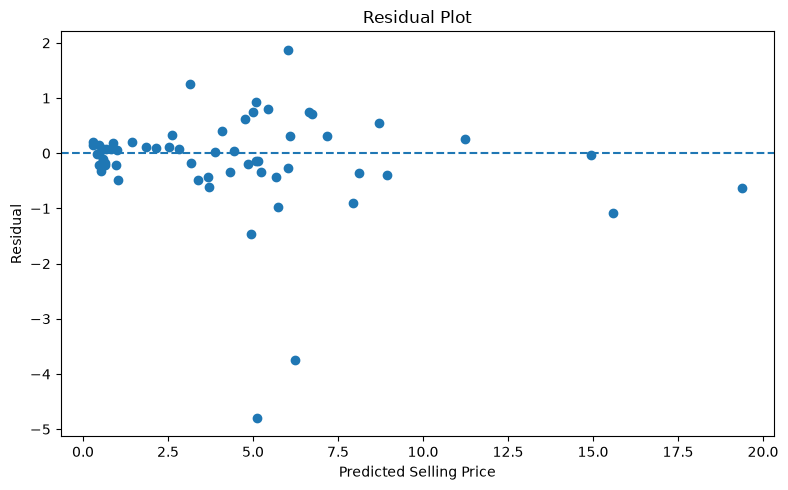

In [84]:
plt.figure(figsize=(8, 5))

plt.scatter(
    best_predictions,
    residuals
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title("Residual Plot")
plt.xlabel("Predicted Selling Price")
plt.ylabel("Residual")

plt.tight_layout()
plt.show()

In [85]:
### Observation

###The residual plot shows the prediction errors of the selected regression model. A good regression model should have residuals distributed around zero without a clear systematic pattern.

In [86]:
# Feature Importance using Random Forest

rf_model = trained_models["Random Forest"]

rf_model_fitted = rf_model.named_steps["model"]
rf_preprocessor = rf_model.named_steps["preprocessor"]

feature_names = rf_preprocessor.get_feature_names_out()
importance = rf_model_fitted.feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
).head(15)

display(feature_importance_df)

,Feature,Importance
0,num__Present_Price,0.887648
3,num__Car_Age,0.065981
1,num__Kms_Driven,0.017926
29,cat__Brand_city,0.004743
30,cat__Brand_corolla,0.003678
9,cat__Transmission_Automatic,0.002803
8,cat__Seller_Type_Individual,0.002451
37,cat__Brand_fortuner,0.002233
10,cat__Transmission_Manual,0.002212
43,cat__Brand_land,0.001815


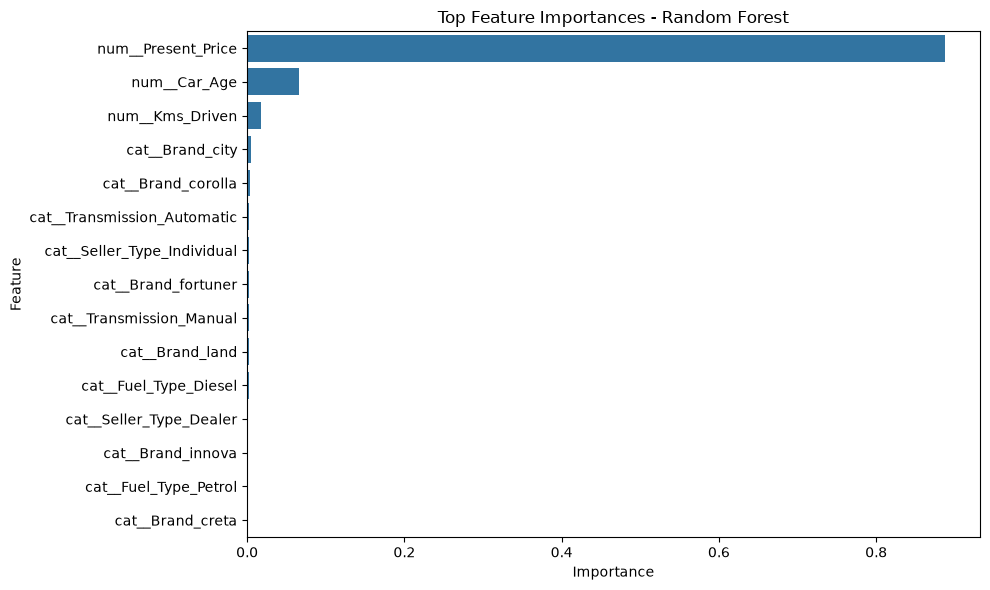

In [87]:
# Feature Importance Plot

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Top Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

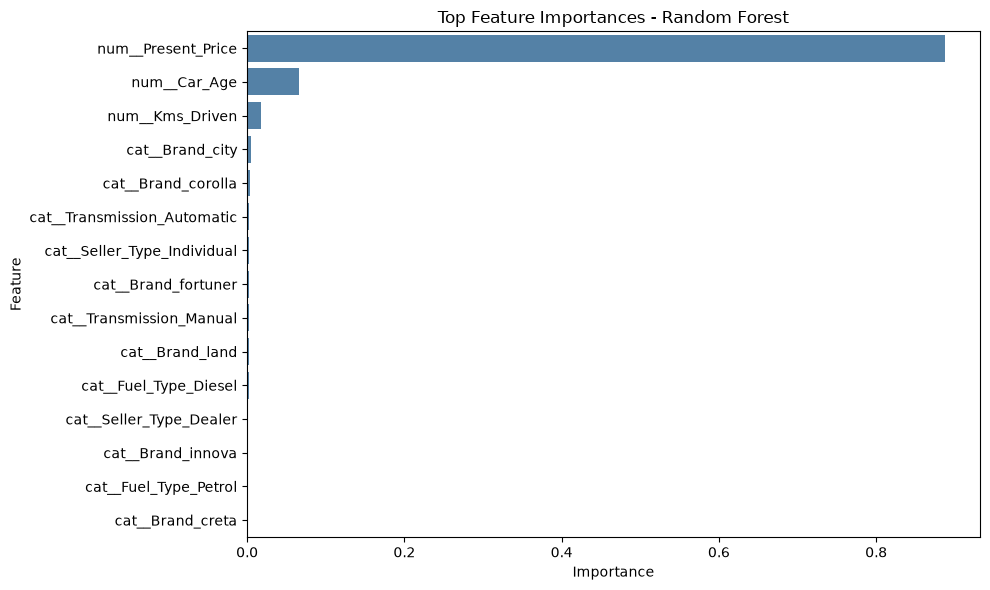

In [88]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance_df,
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title("Top Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [89]:
# Final comparison of all models

final_results = results_df.copy()

display(
    final_results.sort_values(
        by="R2",
        ascending=False
    ).reset_index(drop=True)
)

,Model,R2,RMSE,MAE
0,SVR,0.939698,0.951430,0.521707
1,KNN,0.905382,1.191783,0.739433
2,Gradient Boosting,0.896800,1.244661,0.597612
3,ElasticNet,0.811049,1.684169,1.144449
4,Ridge,0.797919,1.741704,1.160729
5,Lasso,0.793296,1.761511,1.148734
6,Random Forest,0.766983,1.870274,0.790014
7,Linear Regression,0.722704,2.040251,1.263986
8,Decision Tree,0.631308,2.352573,1.004599
9,Polynomial Regression,0.555497,2.583147,1.414191


In [90]:
# Lasso Feature Sparsity

lasso_model = trained_models["Lasso"]

lasso_estimator = lasso_model.named_steps["model"]

lasso_coefficients = lasso_estimator.coef_

zero_coefficients = np.sum(lasso_coefficients == 0)
total_coefficients = len(lasso_coefficients)

print("Total transformed features:", total_coefficients)
print("Zero coefficients:", zero_coefficients)
print("Non-zero coefficients:", total_coefficients - zero_coefficients)

Total transformed features: 53
Zero coefficients: 30
Non-zero coefficients: 23
